# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [ ]:
# %pip install torch torchvision matplotlib

Device: cpu
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


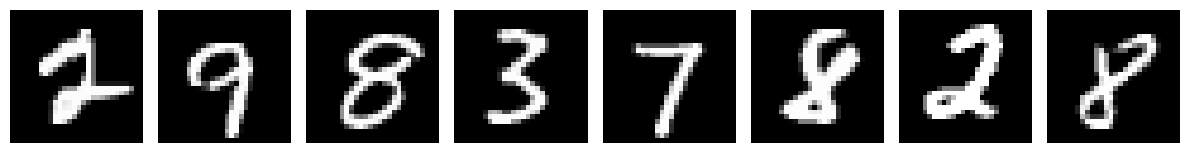

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Answers:**
1. For `L=8`, input values per image = 1×28×28 = 784; latent values = 8×7×7 = 392; input/latent ratio = 784/392 = 2.0.
2. For `L=32`, latent values = 32×7×7 = 1568, which is actually larger than the input (784). So no, it is not dimensionally compressed. The spatial grid is smaller (7×7 vs 28×28), but there are so many channels that the total number of values exceeds the input. Compression happens only when the product C×H×W goes down overall.
3. The final activation is Sigmoid, which maps outputs to [0, 1]. This matches the pixel range of MNIST images after ToTensor(), which also lie in [0, 1]. If we used Tanh (range [-1, 1]) or no activation, the output range would not match the targets and MSE would be higher for no good reason.
4. With output_padding=0 for the first decoder layer: H_out = (H_in - 1)*stride - 2*padding + kernel = (7-1)*2 - 2*1 + 3 = 12 - 2 + 3 = 13. So we would get 13 instead of 14, and the second transpose conv would then give us 25 instead of 28. The output_padding=1 adds one extra row/column to resolve this ambiguity.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1),
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)

In [ ]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z

In [ ]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [ ]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad()
    reconstruction, z = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()

Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04370
Epoch 2: train MSE=0.03428, held-out MSE=0.02552
Epoch 3: train MSE=0.01680, held-out MSE=0.00982
Epoch 4: train MSE=0.00827, held-out MSE=0.00621
Epoch 5: train MSE=0.00572, held-out MSE=0.00460


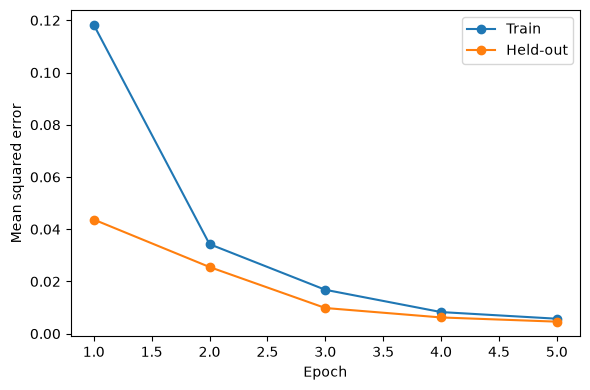

In [ ]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

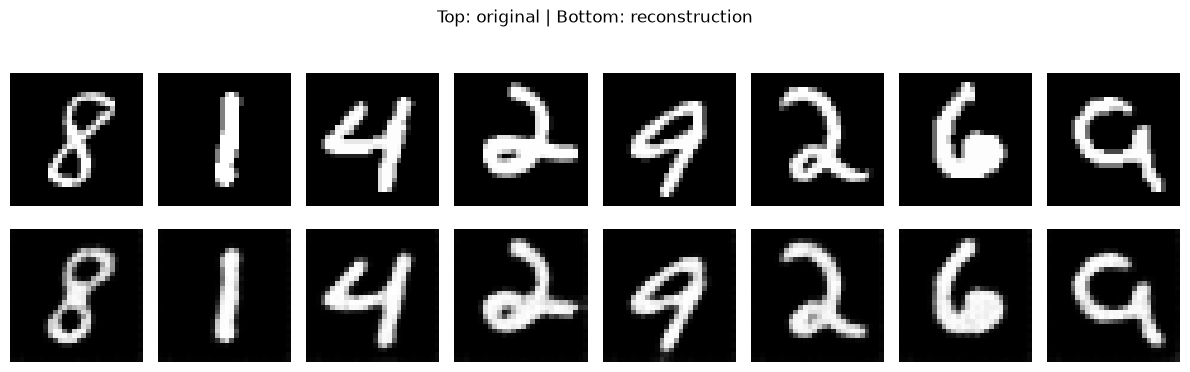

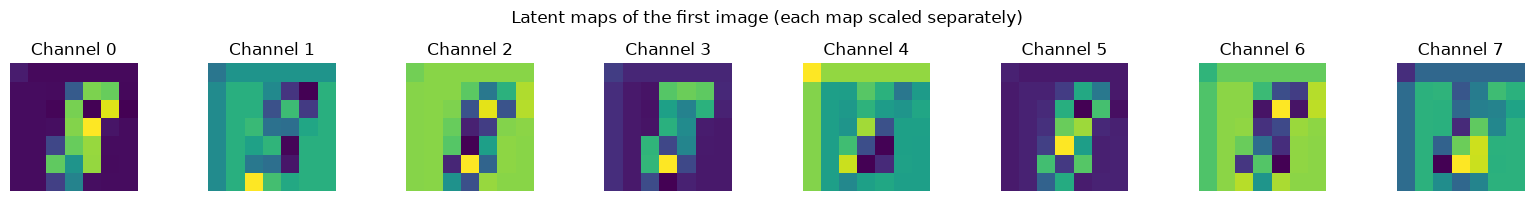

In [ ]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)
Run the lab with `LATENT_CHANNELS = 2`, `8`, and `32`. Change the value in the setup cell and rerun from that cell downward. Keep the data, seed, learning rate, and epoch count fixed. The training cell creates a fresh model each time. Save your observations before the next run.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8.0 | 0.01134 | 0.01073 | Digits are recognizable but blurry, thin strokes lost |
| 8 | 392 | 2.0 | 0.00505 | 0.00466 | Good reconstructions, most details preserved |
| 32 | 1568 | 0.5 | 0.00333 | 0.00316 | Very sharp reconstructions, nearly identical to input |

**Discussion:**
1. Yes, a larger latent generally improved reconstruction in my runs. With L=2 the held-out MSE was 0.01073, with L=8 it dropped to 0.00466, and with L=32 it went down further to 0.00316. Visually the L=2 reconstructions are noticeably blurrier — thin strokes on digits like 1 and 7 get smoothed out, while L=32 reconstructions look almost identical to the originals.
2. Spatial downsampling alone does not guarantee dimensional compression because the number of channels can increase to compensate. With L=32, the latent has 32×7×7 = 1568 values, which is actually more than the 784 input values. The spatial grid shrinks from 28×28 to 7×7, but if you pack enough channels in there, you end up with more total numbers than you started with. True compression means the total count of values drops, not just the spatial size.
3. The decoder can restore the image size through transposed convolutions that upsample spatially, but it can only work with what the latent representation preserves. If fine-grained details (exact stroke edges, pixel-level texture) were lost during encoding, the decoder has no way to recover them — it can only make a plausible smooth approximation. That is why reconstructions look blurry at small L: the decoder fills in the right general shape but cannot hallucinate the precise details back.
4. A [N, 128] flat vector discards all spatial structure — the decoder would have no idea which latent values correspond to which region of the image. Our spatial latent [N, L, 7, 7] keeps a 7×7 grid, so each location in the latent roughly corresponds to a 4×4 patch in the input. This makes the decoder's job easier because it already knows where things are and just needs to upsample and refine.
5. A skip connection could carry the encoder's intermediate feature maps (say, the 16-channel 14×14 map) directly to the corresponding decoder layer. This would let the decoder access high-frequency details that the bottleneck might drop. But it weakens the bottleneck constraint because the network could learn to pass most of the information through the skip connections and barely use the latent at all — which defeats the purpose of having a compressed representation.
6. This exercise trains the model to reconstruct existing images, not to generate new ones. The latent space has no structure that would let us sample random vectors and get meaningful images. If we picked a random z vector, we would likely land in a region the decoder has never seen during training, and the output would be garbage. A VAE or GAN is needed to impose structure on the latent space so that random sampling produces realistic outputs.

## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.